In [108]:
from langchain_openai import ChatOpenAI
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from dotenv import load_dotenv
load_dotenv()
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, List
from langchain_core.messages import SystemMessage, HumanMessage
import re
from pydantic import BaseModel
import os
from langchain_community.tools.tavily_search  import TavilySearchResults

In [109]:
os.environ['LANGCHAIN_PROJECT'] = 'CRAG'

In [110]:
model=ChatOpenAI(model='gpt-5-mini', temperature=0)
emb=HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6866.18it/s]


In [111]:
loader=PyMuPDFLoader("D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf")
docs=loader.load()

In [112]:
docs

[Document(metadata={'producer': '', 'creator': '', 'creationdate': '', 'source': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'file_path': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'total_pages': 5, 'format': 'PDF 1.4', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '', 'trapped': '', 'modDate': '', 'creationDate': '', 'page': 0}, page_content='Machine Learning Fundamentals\nSynthetic study material designed to test RAG chunking and retrieval. The document intentionally places\nrelated but potentially misleading statements near each other. A retrieval system should use the\ncomplete context rather than assuming every retrieved sentence describes the same concept.\nWhat is gradient descent?\nGradient descent is an optimization algorithm used to minimize a loss function. It repeatedly updates\nmodel parameters in the direction of the negative gradient. The learning rate controls how large each\nupdate is.\nA larger learning rate always makes tra

In [113]:
splitter=RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
splitted_docs=splitter.split_documents(docs)

In [114]:
splitted_docs

[Document(metadata={'producer': '', 'creator': '', 'creationdate': '', 'source': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'file_path': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'total_pages': 5, 'format': 'PDF 1.4', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '', 'trapped': '', 'modDate': '', 'creationDate': '', 'page': 0}, page_content='Machine Learning Fundamentals\nSynthetic study material designed to test RAG chunking and retrieval. The document intentionally places\nrelated but potentially misleading statements near each other. A retrieval system should use the\ncomplete context rather than assuming every retrieved sentence describes the same concept.\nWhat is gradient descent?\nGradient descent is an optimization algorithm used to minimize a loss function. It repeatedly updates'),
 Document(metadata={'producer': '', 'creator': '', 'creationdate': '', 'source': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'file_path': 'D:/

In [115]:
vector=FAISS.from_documents(embedding=emb, documents=splitted_docs)
ret=vector.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [116]:
class schema(TypedDict):
    ques:str
    context:List[Document]
    answer:str

    good_docs:List[Document]
    verdict:str
    reason:str

    strips:List[str]
    kept_strips:List[str]
    refined_context:str
    web_query:str

    web_docs:List[Document]

In [117]:
def retriever(state:schema)->dict:
    qs=state['ques']
    rs=ret.invoke(qs)
    return {'context':rs}

In [118]:
def generate(state:schema)->dict:
    qs=state['ques']
    context=state['context']
    rs=model.invoke([SystemMessage(content="Answer only from the context. If not in context, say you don't know."), HumanMessage(content=f'Question:{qs}, Context:{context}')])
    return {'answer':rs.content}

In [119]:
UPPER=0.7
LOWER=0.3

In [ ]:
prompt="""You are a strict retrieval evaluator for RAG.\n
You will be given ONE retrieved chunk and a question.\n
Return a relevance score in [0.0, 1.0].\n
— 1.0: chunk alone is sufficient to answer fully/mostly\n
— 0.0: chunk is irrelevant\n
Be conservative with high scores.\n
Also return a short reason.\n
Output JSON only."""

class k2(BaseModel):
    score:float
    reason:str

eval_model=model.with_structured_output(k2)

def eval(state:schema)->schema:

    scores:List[float]=[]
    reason:List[str]=[]
    good:List[Document]=[]

    qs=state['ques']

    for d in state['context']:
        rs=eval_model.invoke([SystemMessage(content=prompt), HumanMessage(content=f'Question:{qs}, Chunk:{d.page_content}')])
        scores.append(rs.score)
        reason.append(rs.reason)

        if rs.score > LOWER:
            good.append(d)
    # CORRECT ONE
    if any(s >UPPER for s in scores):
        return{
            "good_docs":good,
            "verdict":"CORRECT",
            "reason":f'Scored > {UPPER}'

        }
    # INCORRECT ONE
    if len(scores)>0 and all(s < LOWER for s in scores):
        return {
            "good_docs":[],
            "verdict":"INCORRECT",
            "reason":f'All chunks scored < {LOWER}'
        }

    #AMBIGUOUS ONE
    return {
        "good_docs":good,
        "verdict":"AMBIGUOUS",
        "reason":f"All chunks lie between {UPPER} and {LOWER}"

    }


In [121]:
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

class k1(BaseModel):
    keep:str

klm=model.with_structured_output(k1)
    

def refine(state:schema)->dict:
    qs=state['ques']

    if state['verdict'] == "CORRECT":
        ddoc= state['good_docs']
    elif state['verdict'] == "INCORRECT":
        ddoc= state['web_docs']
    else:
        ddoc=state['good_docs'] + state['web_docs']

    docs="\n\n".join([d.page_content for d in ddoc]).strip()

    strips=decompose_to_sentences(docs)

    kept:List[str]=[]

    for s in strips:
        if klm.invoke([SystemMessage(content="You are a strict relevance filter, Return keep=true only if the sentence directly helps answer the question. Use ONLY the sentence. Output JSON only"), HumanMessage(content=f'Question:{qs}, Sentence:{s}')]).keep:
            kept.append(s)


    refined_context="\n".join(kept).strip()

    return{'strips':strips, 'kept_strips':kept,'refined_context':refined_context}


    

    

In [122]:

def route_eval(state:schema)->str:
    if state['verdict'] == "CORRECT":
        return "refine"
    else:
        return "rewrite"

In [123]:
tavily=TavilySearchResults(max_results=5)

def web_search(state:schema)->schema:
    qs=state['web_query'] or state['ques']

    rs=tavily.invoke({'query':qs})
    web_docs=[]

    for r in rs or []:
        title=r.get("title","")
        url=r.get("url","")
        content=r.get("content","") or r.get("snippet","")

        text=f'Title:{title},\n URL:{url},\n Content:{content}'

        web_docs.append(Document(page_content=text, metadata={"url":url, "title":title} ))

        return {"web_docs":web_docs}


In [124]:
class rs1(BaseModel):
    query:str

def rewrite(state:schema)->schema:
    prompt="""Rewrite the user question into a web search query composed of keywords.
    Rules:
    - Keep it short (6–14 words).
    - If the question implies recency (e.g., recent/latest/last week/last month), add a constraint like (last 30 days).
    - Do NOT answer the question.
    - Return JSON with a single key: query"""
    qs=state['ques']

    rs=model.with_structured_output(rs1).invoke([SystemMessage(content=prompt), HumanMessage(content=f'Query:{qs}')])
    return {'web_query':rs.query}

In [125]:
graph=StateGraph(schema)
graph.add_node('retriever', retriever)
graph.add_node('generate', generate)
graph.add_node('refine', refine)
graph.add_node('eval', eval)
graph.add_node('web_search', web_search)
graph.add_node('rewrite', rewrite)

graph.add_edge(START, 'retriever')
graph.add_edge('retriever','eval')
graph.add_conditional_edges('eval',route_eval, {"refine":"refine", "rewrite":"rewrite"})
graph.add_edge('rewrite','web_search')
graph.add_edge("web_search", 'refine')
graph.add_edge('refine', 'generate')
graph.add_edge('generate', END)


wf=graph.compile()

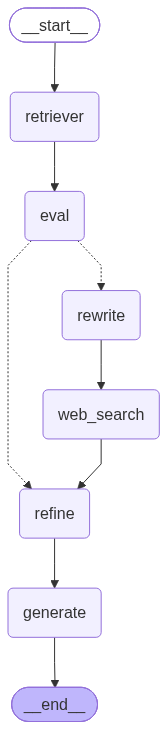

In [126]:
wf

In [130]:
rs=wf.invoke({'ques':'what are gradient descent'})

In [131]:
print("\n",rs['answer'])


 From the provided context:

- Gradient descent is an optimization algorithm used to minimize a loss function.  
- It repeatedly updates the model parameters in the direction of the negative gradient.  
- The learning rate controls how large each update is.  
- A larger learning rate does not always improve accuracy; the best learning rate depends on the model, data, and optimization problem.


In [132]:
rs['verdict']

'CORRECT'

In [133]:
rs['reason']

'Scored > 0.7'

In [ ]:
print(rs['kept_strips'])

In [ ]:
print(rs['context'])